# Binary Risk Classification — DenseNet-121 (7-Channel Fusion + CBAM) v3
## Raw DPT + Composite Overlay Early Fusion with Attention

**Author:** Minu  
**Supervisor:** Dr. Prasan Yapa

---

### Architecture
- **7-channel input**: CLAHE raw DPT (×3) + Sobel edge map (×1) + Composite overlay (×3)
- **Backbone**: DenseNet-121, first conv modified 3→7 channels
- **Attention**: CBAM (Channel + Spatial) after backbone features

### v3 Key Settings
| Component | Value |
|-----------|-------|
| Rotation | ±20° |
| Translation | 15% |
| Zoom | 0.85–1.15× |
| Brightness/contrast | ±20% raw DPT only |
| Gaussian noise | σ=0.05 raw DPT only |
| Random erasing | 5–20% region |
| Pre-CBAM dropout | 0.3 |
| Classifier dropout | 0.6 |
| Loss | CrossEntropy + label_smoothing=0.1 |
| Early stopping | patience=12 on val loss |
| Max epochs | 80 |
| CBAM channels | 1024 (DenseNet-121 output) |

### ⚠️ Before Running
1. Update `RAW_DPT_DIR` to your raw DPT images folder
2. Confirm filenames match between raw and overlay folders
3. `FORCE_REBUILD = True` rebuilds cache from scratch


In [ ]:
# Check GPU
import torch
print(f"PyTorch: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")


PyTorch: 2.10.0+cu128
CUDA Available: True
GPU: Tesla T4
Memory: 15.64 GB


In [ ]:
# Mount Drive
try:
    from google.colab import drive
    drive.mount('/content/drive')
    print('✅ Drive mounted')
except:
    print('Not in Colab or already mounted')


Mounted at /content/drive
✅ Drive mounted


In [ ]:
# Imports
import cv2
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import os
import random
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torchvision.transforms.functional as TF
from PIL import Image
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms as transforms
from torchvision import models
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve,
    precision_recall_curve, average_precision_score,
    precision_recall_fscore_support
)
import warnings
warnings.filterwarnings('ignore')

def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
print("✅ Imports complete")


✅ Imports complete


## Configure Paths


In [ ]:
RAW_DPT_DIR = "/content/drive/MyDrive/FINAL_YEAR/DPT_1234new"          # raw DPT images
OVERLAY_DIR = "/content/drive/MyDrive/FINAL_YEAR/DPT_1234new/Classify_dataset"  # composite overlays
EXCEL_PATH  = "/content/drive/MyDrive/FINAL_YEAR/DPT_1234new/Risk_assessment.xlsx"
OUTPUT_DIR  = "/content/drive/MyDrive/FINAL_YEAR/binary_results_densenet_7ch_cbam"
CACHE_PATH  = os.path.join(OUTPUT_DIR, "matched_data_cache.csv")

os.makedirs(OUTPUT_DIR, exist_ok=True)
CROPPED_RAW_DIR     = os.path.join(OUTPUT_DIR, 'cropped_raw')
CROPPED_OVERLAY_DIR = os.path.join(OUTPUT_DIR, 'cropped_overlay')
os.makedirs(CROPPED_RAW_DIR, exist_ok=True)
os.makedirs(CROPPED_OVERLAY_DIR, exist_ok=True)

print("📁 Paths configured")
print(f"   Raw DPT dir    : {RAW_DPT_DIR}")
print(f"   Overlay dir    : {OVERLAY_DIR}")
print(f"   Output dir     : {OUTPUT_DIR}")


📁 Paths configured
   Raw DPT dir    : /content/drive/MyDrive/FINAL_YEAR/DPT_1234new
   Overlay dir    : /content/drive/MyDrive/FINAL_YEAR/DPT_1234new/Classify_dataset
   Output dir     : /content/drive/MyDrive/FINAL_YEAR/binary_results_densenet_7ch_cbam


## Helper Functions (crops BOTH raw + overlay)


In [ ]:
def crop_image_by_side(image_path, side, output_dir):
    """Crop DPT at midline to isolate left or right side."""
    img = Image.open(image_path)
    width, height = img.size
    midline = width // 2
    if side == 'LS':
        cropped = img.crop((0, 0, midline, height))
    elif side == 'RS':
        cropped = img.crop((midline, 0, width, height))
    else:
        raise ValueError(f"Invalid side: {side}")
    base_name = os.path.splitext(os.path.basename(image_path))[0]
    output_path = os.path.join(output_dir, f"{base_name}_{side}.jpg")
    cropped.save(output_path, quality=95)
    return output_path

def normalize_dpt_number(dpt_str):
    return str(dpt_str).strip().replace(' ', '').replace('-', '').upper()

def strict_match_dpt(excel_dpt, image_mapping):
    if excel_dpt in image_mapping:
        return image_mapping[excel_dpt], 'exact'
    excel_normalized = normalize_dpt_number(excel_dpt)
    matches = [(k, v) for k, v in image_mapping.items()
               if normalize_dpt_number(k) == excel_normalized]
    if len(matches) == 1:
        return matches[0][1], 'normalized'
    elif len(matches) > 1:
        return None, 'ambiguous'
    return None, 'no_match'

print("✅ Helper functions defined")


✅ Helper functions defined


## Data Loading with Caching (crops BOTH raw + overlay)


In [ ]:
FORCE_REBUILD = True  # Set False after first run to use cache

if os.path.exists(CACHE_PATH) and not FORCE_REBUILD:
    print("✅ Cache found — loading instantly...")
    df_matched  = pd.read_csv(CACHE_PATH)
    used_images = df_matched.groupby('original_image')['dpt_no'].apply(list).to_dict()
    print(f"   Loaded {len(df_matched)} rows | {len(used_images)} unique images")
    print("\n📊 Risk Distribution:")
    print(df_matched['risk_level'].value_counts())

else:
    print("🔍 Building cache from scratch...")

    df = pd.read_excel(EXCEL_PATH).dropna(subset=['DPT no'])
    print(f"Excel rows: {len(df)}")

    def build_mapping(directory):
        mapping = {}
        for img_name in os.listdir(directory):
            if img_name.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp')):
                base = os.path.splitext(img_name)[0]
                mapping[base] = os.path.join(directory, img_name)
        return mapping

    raw_mapping     = build_mapping(RAW_DPT_DIR)
    overlay_mapping = build_mapping(OVERLAY_DIR)
    print(f"Raw images: {len(raw_mapping)} | Overlay images: {len(overlay_mapping)}")

    matched_data = []
    match_stats  = {'exact': 0, 'normalized': 0, 'ambiguous': 0,
                    'no_match': 0, 'no_overlay': 0, 'error': 0}
    used_images  = {}

    for idx, row in df.iterrows():
        if idx % 100 == 0:
            print(f"  Processing {idx}/{len(df)}...")

        dpt_no      = str(row['DPT no']).strip()
        side        = row['Side']
        risk_level  = row['Level of Risk of nerve damage']
        binary_risk = 'Low' if risk_level == 'Low' else 'High-Risk'

        raw_path, match_type = strict_match_dpt(dpt_no, raw_mapping)
        if raw_path is None:
            match_stats[match_type] += 1
            continue

        overlay_path, _ = strict_match_dpt(dpt_no, overlay_mapping)
        if overlay_path is None:
            match_stats['no_overlay'] += 1
            continue

        try:
            cropped_raw     = crop_image_by_side(raw_path,     side, CROPPED_RAW_DIR)
            cropped_overlay = crop_image_by_side(overlay_path, side, CROPPED_OVERLAY_DIR)

            original_img = os.path.basename(raw_path)
            used_images.setdefault(original_img, []).append((dpt_no, side))

            matched_data.append({
                'raw_path':      cropped_raw,
                'overlay_path':  cropped_overlay,
                'risk_level':    binary_risk,
                'original_risk': risk_level,
                'dpt_no':        dpt_no,
                'side':          side,
                'original_image': original_img,
                'match_type':    match_type
            })
            match_stats[match_type] += 1

        except Exception as e:
            print(f"⚠️ Error: {dpt_no} {side}: {e}")
            match_stats['error'] += 1

    df_matched = pd.DataFrame(matched_data)
    print(f"\n✅ Matched: {len(df_matched)} | Unique images: {len(used_images)}")
    print(f"Match stats: {match_stats}")

    print("\n📊 Risk Distribution:")
    print(df_matched['risk_level'].value_counts())

    # Duplicate check
    dup_check  = df_matched['raw_path'].value_counts()
    duplicates = dup_check[dup_check > 1]
    if len(duplicates) > 0:
        print(f"\n⚠️ WARNING: {len(duplicates)} duplicates!")
    else:
        print("\n✅ NO DUPLICATES!")

    df_matched.to_csv(CACHE_PATH, index=False)
    print(f"\n💾 Cache saved: {CACHE_PATH}")


🔍 Building cache from scratch...
Excel rows: 1093
Raw images: 484 | Overlay images: 483
  Processing 0/1093...


## CLAHE + Sobel Preprocessing Utilities


In [ ]:
def apply_clahe(pil_img):
    """
    Apply CLAHE to a PIL image (operates on L channel in LAB space).
    Amplifies canal narrowing and darkening which are subtle in raw DPTs.
    """
    img_np  = np.array(pil_img.convert('RGB'))
    img_lab = cv2.cvtColor(img_np, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(img_lab)
    clahe   = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l_enh   = clahe.apply(l)
    img_enh = cv2.merge([l_enh, a, b])
    img_enh = cv2.cvtColor(img_enh, cv2.COLOR_LAB2RGB)
    return Image.fromarray(img_enh)


def compute_sobel_channel(pil_img):
    """
    Compute Sobel edge magnitude map.
    Canal narrowing changes edge spacing; a narrowed canal has edges closer together.
    """
    gray      = np.array(pil_img.convert('L')).astype(np.float32)
    sobelx    = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
    sobely    = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
    magnitude = np.sqrt(sobelx**2 + sobely**2)
    magnitude = (magnitude / (magnitude.max() + 1e-8) * 255).astype(np.uint8)
    return Image.fromarray(magnitude, mode='L')


print("✅ CLAHE and Sobel utilities defined")
print("   CLAHE  → amplifies canal narrowing + darkening in raw DPT")
print("   Sobel  → explicit structural width signal for canal narrowing")


✅ CLAHE and Sobel utilities defined
   CLAHE  → amplifies canal narrowing + darkening in raw DPT
   Sobel  → explicit structural width signal for canal narrowing


## 7-Channel Dataset Class (Channel-Aware Augmentation)


In [ ]:
class DPTDataset7Ch(Dataset):
    """
    7-channel dataset with channel-aware augmentation.

    Channel layout:
      Ch 0-2 : CLAHE-enhanced raw DPT  — intensity, darkening
      Ch 3   : Sobel edge map          — canal narrowing / structural width
      Ch 4-6 : Composite overlay       — spatial overlap, IAN-M3M proximity

    Augmentation rules:
      Spatial (flip, rotate, translate, zoom): same params applied to BOTH images
      Brightness/contrast jitter: raw DPT ONLY (overlay colour encodes class)
      Gaussian noise:             raw DPT ONLY
      Random erasing:             full 7ch tensor
    """
    def __init__(self, raw_paths, overlay_paths, labels,
                 img_size=224, augment=False):
        self.raw_paths     = raw_paths
        self.overlay_paths = overlay_paths
        self.labels        = labels
        self.img_size      = img_size
        self.augment       = augment
        self.mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
        self.std  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

    def __len__(self):
        return len(self.raw_paths)

    def _spatial_augment(self, raw_pil, overlay_pil):
        """Identical spatial transforms applied to both images."""
        if random.random() < 0.5:
            raw_pil     = raw_pil.transpose(Image.FLIP_LEFT_RIGHT)
            overlay_pil = overlay_pil.transpose(Image.FLIP_LEFT_RIGHT)

        if random.random() < 0.8:
            angle       = random.uniform(-20, 20)
            raw_pil     = raw_pil.rotate(angle, resample=Image.BILINEAR, fillcolor=0)
            overlay_pil = overlay_pil.rotate(angle, resample=Image.BILINEAR, fillcolor=0)

        if random.random() < 0.5:
            tx = random.uniform(-0.15, 0.15) * self.img_size
            ty = random.uniform(-0.15, 0.15) * self.img_size
            raw_pil     = raw_pil.transform(
                raw_pil.size, Image.AFFINE, (1, 0, tx, 0, 1, ty), resample=Image.BILINEAR)
            overlay_pil = overlay_pil.transform(
                overlay_pil.size, Image.AFFINE, (1, 0, tx, 0, 1, ty), resample=Image.BILINEAR)

        if random.random() < 0.5:
            scale       = random.uniform(0.85, 1.15)
            new_size    = int(self.img_size * scale)
            raw_pil     = raw_pil.resize((new_size, new_size), Image.BILINEAR)
            overlay_pil = overlay_pil.resize((new_size, new_size), Image.BILINEAR)

        # Crop/pad back to img_size
        def center_crop_or_pad(img):
            w, h   = img.size
            s      = self.img_size
            if w >= s and h >= s:
                left = (w - s) // 2; top = (h - s) // 2
                return img.crop((left, top, left + s, top + s))
            canvas = Image.new(img.mode, (s, s), 0)
            canvas.paste(img, ((s - w) // 2, (s - h) // 2))
            return canvas

        return center_crop_or_pad(raw_pil), center_crop_or_pad(overlay_pil)

    def __getitem__(self, idx):
        raw_pil     = Image.open(self.raw_paths[idx]).convert('RGB')
        overlay_pil = Image.open(self.overlay_paths[idx]).convert('RGB')
        label       = self.labels[idx]

        raw_pil = apply_clahe(raw_pil)

        raw_pil     = raw_pil.resize((self.img_size, self.img_size), Image.BILINEAR)
        overlay_pil = overlay_pil.resize((self.img_size, self.img_size), Image.BILINEAR)

        if self.augment:
            raw_pil, overlay_pil = self._spatial_augment(raw_pil, overlay_pil)

        # Compute Sobel on CLAHE-processed raw
        sobel_pil = compute_sobel_channel(raw_pil)

        # Raw DPT-only photometric augmentation
        if self.augment:
            if random.random() < 0.5:
                factor  = random.uniform(0.8, 1.2)
                raw_pil = TF.adjust_brightness(raw_pil, factor)
            if random.random() < 0.5:
                factor  = random.uniform(0.8, 1.2)
                raw_pil = TF.adjust_contrast(raw_pil, factor)

        # Convert to tensors
        raw_np     = np.array(raw_pil).astype(np.float32) / 255.0
        overlay_np = np.array(overlay_pil).astype(np.float32) / 255.0
        sobel_np   = np.array(sobel_pil).astype(np.float32) / 255.0

        # ImageNet normalisation on raw and overlay RGB channels
        raw_np     = (raw_np - self.mean) / self.std
        overlay_np = (overlay_np - self.mean) / self.std

        # Add Gaussian noise to raw only
        if self.augment and random.random() < 0.5:
            raw_np = raw_np + np.random.normal(0, 0.05, raw_np.shape).astype(np.float32)

        # Build 7-channel tensor: (H,W,3)+(H,W,1)+(H,W,3) → (7,H,W)
        ch_raw     = torch.from_numpy(raw_np.transpose(2, 0, 1))          # (3,H,W)
        ch_sobel   = torch.from_numpy(sobel_np[np.newaxis])               # (1,H,W)
        ch_overlay = torch.from_numpy(overlay_np.transpose(2, 0, 1))      # (3,H,W)
        tensor_7ch = torch.cat([ch_raw, ch_sobel, ch_overlay], dim=0)     # (7,H,W)

        # Random erasing on full tensor
        if self.augment and random.random() < 0.5:
            _, h, w  = tensor_7ch.shape
            erase_h  = random.randint(int(0.05 * h), int(0.20 * h))
            erase_w  = random.randint(int(0.05 * w), int(0.20 * w))
            top      = random.randint(0, h - erase_h)
            left     = random.randint(0, w - erase_w)
            tensor_7ch[:, top:top+erase_h, left:left+erase_w] = 0

        return tensor_7ch, label, self.raw_paths[idx]


print("✅ DPTDataset7Ch defined")
print("   Spatial : flip | ±20° rot | 15% translate | 0.85-1.15x zoom")
print("   Raw only: brightness/contrast ±20% | Gaussian noise σ=0.05")
print("   Tensor  : random erasing 5-20% region")


✅ DPTDataset7Ch defined
   Spatial : flip | ±20° rot | 15% translate | 0.85-1.15x zoom
   Raw only: brightness/contrast ±20% | Gaussian noise σ=0.05
   Tensor  : random erasing 5-20% region


## CBAM Attention Module


In [ ]:
# CBAM = Convolutional Block Attention Module (Woo et al. 2018)
# Channel attention → upweights Sobel/CLAHE channels when structural signal is present
# Spatial attention → focuses on canal/root region guided by overlay colour areas

class ChannelAttention(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.mlp = nn.Sequential(
            nn.Flatten(),
            nn.Linear(channels, channels // reduction, bias=False),
            nn.ReLU(),
            nn.Linear(channels // reduction, channels, bias=False),
        )
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_w = self.mlp(self.avg_pool(x))
        max_w = self.mlp(self.max_pool(x))
        scale = self.sigmoid(avg_w + max_w).unsqueeze(-1).unsqueeze(-1)
        return x * scale


class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        self.conv    = nn.Conv2d(2, 1, kernel_size, padding=kernel_size // 2, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_map         = x.mean(dim=1, keepdim=True)
        max_map, _      = x.max(dim=1, keepdim=True)
        spatial         = torch.cat([avg_map, max_map], dim=1)
        scale           = self.sigmoid(self.conv(spatial))
        return x * scale


class CBAM(nn.Module):
    def __init__(self, channels, reduction=16, kernel_size=7):
        super().__init__()
        self.channel_attn = ChannelAttention(channels, reduction)
        self.spatial_attn = SpatialAttention(kernel_size)

    def forward(self, x):
        x = self.channel_attn(x)
        x = self.spatial_attn(x)
        return x


print("✅ CBAM attention module defined")


✅ CBAM attention module defined


## 7-Channel DenseNet-121 with CBAM


In [ ]:
class DenseNet121_7Ch_CBAM(nn.Module):
    """
    DenseNet-121, 7-channel input, CBAM attention.

    Channel map:
      0-2 : CLAHE-enhanced raw DPT  → darkening, intensity patterns
      3   : Sobel edge map          → canal narrowing, structural width
      4-6 : Composite overlay       → spatial overlap, IAN-M3M proximity

    Modifications:
      - features.conv0 widened 3→7 channels
      - Dropout(0.3) before CBAM (regularises backbone output)
      - CBAM applied on 1024-channel feature map
      - Classifier dropout = 0.6

    Weight init:
      Ch 0-2 → pretrained ImageNet RGB weights
      Ch 3   → mean of pretrained RGB weights
      Ch 4-6 → pretrained ImageNet RGB weights
    """
    def __init__(self, num_classes=2, dropout=0.6):
        super().__init__()

        densenet = models.densenet121(pretrained=True)

        # Replace first conv: Conv2d(3,64,7,stride=2,padding=3) → Conv2d(7,64,...)
        old_conv = densenet.features.conv0
        new_conv = nn.Conv2d(
            in_channels=7,
            out_channels=old_conv.out_channels,
            kernel_size=old_conv.kernel_size,
            stride=old_conv.stride,
            padding=old_conv.padding,
            bias=False
        )
        with torch.no_grad():
            pretrained_w = old_conv.weight.data          # (64, 3, 7, 7)
            new_conv.weight[:, 0:3, :, :] = pretrained_w
            new_conv.weight[:, 3:4, :, :] = pretrained_w.mean(dim=1, keepdim=True)
            new_conv.weight[:, 4:7, :, :] = pretrained_w

        densenet.features.conv0 = new_conv
        self.backbone = densenet.features   # outputs (B, 1024, H, W)
        self.relu     = nn.ReLU(inplace=True)
        self.pool     = nn.AdaptiveAvgPool2d(1)

        self.pre_cbam_dropout = nn.Dropout(p=0.3)
        self.cbam = CBAM(channels=1024, reduction=16, kernel_size=7)

        self.classifier = nn.Sequential(
            nn.Dropout(p=dropout),
            nn.Linear(1024, num_classes)
        )

    def forward(self, x):
        features = self.backbone(x)          # (B, 1024, H, W)
        features = self.relu(features)       # DenseNet needs explicit ReLU after norm5
        features = self.pre_cbam_dropout(features)
        features = self.cbam(features)
        pooled   = self.pool(features)       # (B, 1024, 1, 1)
        flat     = pooled.flatten(1)         # (B, 1024)
        return self.classifier(flat)


device     = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
test_model = DenseNet121_7Ch_CBAM(num_classes=2).to(device)
total_params = sum(p.numel() for p in test_model.parameters())
print(f"✅ DenseNet121_7Ch_CBAM built")
print(f"   Parameters  : {total_params:,}")
print(f"   Input shape : (B, 7, 224, 224)")
print(f"   CBAM on     : 1024 channels (DenseNet-121 output)")
print(f"   Dropout     : pre-CBAM=0.3, classifier=0.6")

# Sanity check
dummy  = torch.zeros(2, 7, 224, 224).to(device)
out    = test_model(dummy)
print(f"   Output shape: {out.shape} ✅")
del test_model


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 129MB/s]


✅ DenseNet121_7Ch_CBAM built
   Parameters  : 7,099,620
   Input shape : (B, 7, 224, 224)
   CBAM on     : 1024 channels (DenseNet-121 output)
   Dropout     : pre-CBAM=0.3, classifier=0.6
   Output shape: torch.Size([2, 2]) ✅


## Data Preparation


In [ ]:
class_to_idx = {'Low': 0, 'High-Risk': 1}
idx_to_class = {v: k for k, v in class_to_idx.items()}

labels        = df_matched['risk_level'].map(class_to_idx).values
raw_paths     = df_matched['raw_path'].values
overlay_paths = df_matched['overlay_path'].values

# Stratified split: 70% train / 10% val / 20% test
(X_temp_r, X_test_r,
 X_temp_o, X_test_o,
 y_temp,   y_test) = train_test_split(
    raw_paths, overlay_paths, labels,
    test_size=0.2, stratify=labels, random_state=42
)
(X_train_r, X_val_r,
 X_train_o, X_val_o,
 y_train,   y_val) = train_test_split(
    X_temp_r, X_temp_o, y_temp,
    test_size=0.125, stratify=y_temp, random_state=42
)

print(f"Train: {len(X_train_r)} | Val: {len(X_val_r)} | Test: {len(X_test_r)}")
for name, y in [('Train', y_train), ('Val', y_val), ('Test', y_test)]:
    vals, cnts = np.unique(y, return_counts=True)
    print(f"  {name}: " + " | ".join(f"{idx_to_class[v]}={c}" for v, c in zip(vals, cnts)))

IMG_SIZE      = 224
train_dataset = DPTDataset7Ch(X_train_r, X_train_o, y_train, IMG_SIZE, augment=True)
val_dataset   = DPTDataset7Ch(X_val_r,   X_val_o,   y_val,   IMG_SIZE, augment=False)
test_dataset  = DPTDataset7Ch(X_test_r,  X_test_o,  y_test,  IMG_SIZE, augment=False)

# WeightedRandomSampler for class imbalance
class_counts   = np.bincount(y_train)
sample_weights = (1. / class_counts)[y_train]
sampler        = WeightedRandomSampler(sample_weights, len(sample_weights), replacement=True)

BATCH_SIZE   = 16  # 7-channel images use more memory per batch
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=sampler,
                          num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=2, pin_memory=True)

print(f"\n✅ Data loaders ready (batch={BATCH_SIZE}, 7-channel, augment=train only)")


Train: 498 | Val: 72 | Test: 143
  Train: Low=412 | High-Risk=86
  Val: Low=60 | High-Risk=12
  Test: Low=118 | High-Risk=25

✅ Data loaders ready (batch=16, 7-channel, augment=train only)


## Model Setup


In [ ]:
MODEL_NAME = 'densenet121_7ch_cbam_v3'
model      = DenseNet121_7Ch_CBAM(num_classes=2, dropout=0.6).to(device)

class_weights_arr = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights_t   = torch.FloatTensor(class_weights_arr).to(device)
print(f"Class weights: {class_weights_t}")

# Label smoothing prevents overconfident predictions
criterion = nn.CrossEntropyLoss(weight=class_weights_t, label_smoothing=0.1)

optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=5
)

EARLY_STOPPING_PATIENCE = 12

print(f"\n✅ Model, loss, optimizer ready | Device: {device}")
print(f"   Label smoothing     : 0.1")
print(f"   Early stop patience : {EARLY_STOPPING_PATIENCE} epochs on val loss")


Class weights: tensor([0.6044, 2.8953], device='cuda:0')

✅ Model, loss, optimizer ready | Device: cuda
   Label smoothing     : 0.1
   Early stop patience : 12 epochs on val loss


## Training Loop


In [ ]:
EPOCHS            = 80
history           = {'train_loss': [], 'train_acc': [],
                     'val_loss':   [], 'val_acc':   [], 'learning_rates': []}
best_val_loss     = float('inf')
best_val_acc      = 0.0
best_model_path   = os.path.join(OUTPUT_DIR, f'{MODEL_NAME}_best.pth')
epochs_no_improve = 0

print("=" * 60)
print(f"🚀 TRAINING {MODEL_NAME.upper()}")
print("=" * 60)
print(f"Max epochs: {EPOCHS} | Early stop patience: {EARLY_STOPPING_PATIENCE}")
print(f"Batch: {BATCH_SIZE} | Device: {device}\n")

for epoch in range(EPOCHS):

    # --- Train ---
    model.train()
    train_loss, train_correct, train_total = 0.0, 0, 0
    for imgs_7ch, labels_b, _ in train_loader:
        imgs_7ch, labels_b = imgs_7ch.to(device), labels_b.to(device)
        optimizer.zero_grad()
        out  = model(imgs_7ch)
        loss = criterion(out, labels_b)
        loss.backward()
        optimizer.step()
        train_loss    += loss.item() * imgs_7ch.size(0)
        _, pred        = torch.max(out, 1)
        train_total   += labels_b.size(0)
        train_correct += (pred == labels_b).sum().item()

    train_loss /= train_total
    train_acc   = 100.0 * train_correct / train_total

    # --- Validate ---
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for imgs_7ch, labels_b, _ in val_loader:
            imgs_7ch, labels_b = imgs_7ch.to(device), labels_b.to(device)
            out  = model(imgs_7ch)
            loss = criterion(out, labels_b)
            val_loss    += loss.item() * imgs_7ch.size(0)
            _, pred      = torch.max(out, 1)
            val_total   += labels_b.size(0)
            val_correct += (pred == labels_b).sum().item()

    val_loss /= val_total
    val_acc   = 100.0 * val_correct / val_total

    scheduler.step(val_loss)
    current_lr = optimizer.param_groups[0]['lr']

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['learning_rates'].append(current_lr)

    # Save on best val loss
    if val_loss < best_val_loss:
        best_val_loss     = val_loss
        best_val_acc      = val_acc
        epochs_no_improve = 0
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'val_acc':  val_acc,
            'val_loss': val_loss,
        }, best_model_path)
        suffix = ' ← saved'
    else:
        epochs_no_improve += 1
        suffix = ''

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1:3d}/{EPOCHS}] | "
              f"Train: Loss={train_loss:.4f} Acc={train_acc:6.2f}% | "
              f"Val: Loss={val_loss:.4f} Acc={val_acc:6.2f}% | "
              f"LR={current_lr:.6f}{suffix}")

    if epochs_no_improve >= EARLY_STOPPING_PATIENCE:
        print(f"\n⏹️  Early stopping at epoch {epoch+1} "
              f"(no val loss improvement for {EARLY_STOPPING_PATIENCE} epochs)")
        break

print(f"\n{'='*60}")
print(f"✅ Training Complete!")
print(f"   Best Val Loss     : {best_val_loss:.4f}")
print(f"   Best Val Accuracy : {best_val_acc:.2f}%")
print(f"   Model saved       : {best_model_path}")

# Save history
history_df   = pd.DataFrame(history)
history_path = os.path.join(OUTPUT_DIR, f'{MODEL_NAME}_history.csv')
history_df.to_csv(history_path, index=False)
print(f"{'='*60}")


🚀 TRAINING DENSENET121_7CH_CBAM_V3
Max epochs: 80 | Early stop patience: 12
Batch: 16 | Device: cuda

Epoch [  1/80] | Train: Loss=0.4680 Acc= 47.59% | Val: Loss=0.7505 Acc= 16.67% | LR=0.001000 ← saved
Epoch [  5/80] | Train: Loss=0.4320 Acc= 45.78% | Val: Loss=0.9164 Acc= 16.67% | LR=0.001000
Epoch [ 10/80] | Train: Loss=0.4273 Acc= 48.39% | Val: Loss=0.6413 Acc= 52.78% | LR=0.001000
Epoch [ 15/80] | Train: Loss=0.3950 Acc= 53.21% | Val: Loss=0.6745 Acc= 23.61% | LR=0.001000
Epoch [ 20/80] | Train: Loss=0.3857 Acc= 55.22% | Val: Loss=0.5932 Acc= 70.83% | LR=0.000500

⏹️  Early stopping at epoch 24 (no val loss improvement for 12 epochs)

✅ Training Complete!
   Best Val Loss     : 0.5494
   Best Val Accuracy : 81.94%
   Model saved       : /content/drive/MyDrive/FINAL_YEAR/binary_results_densenet_7ch_cbam/densenet121_7ch_cbam_v3_best.pth


## Training Visualization


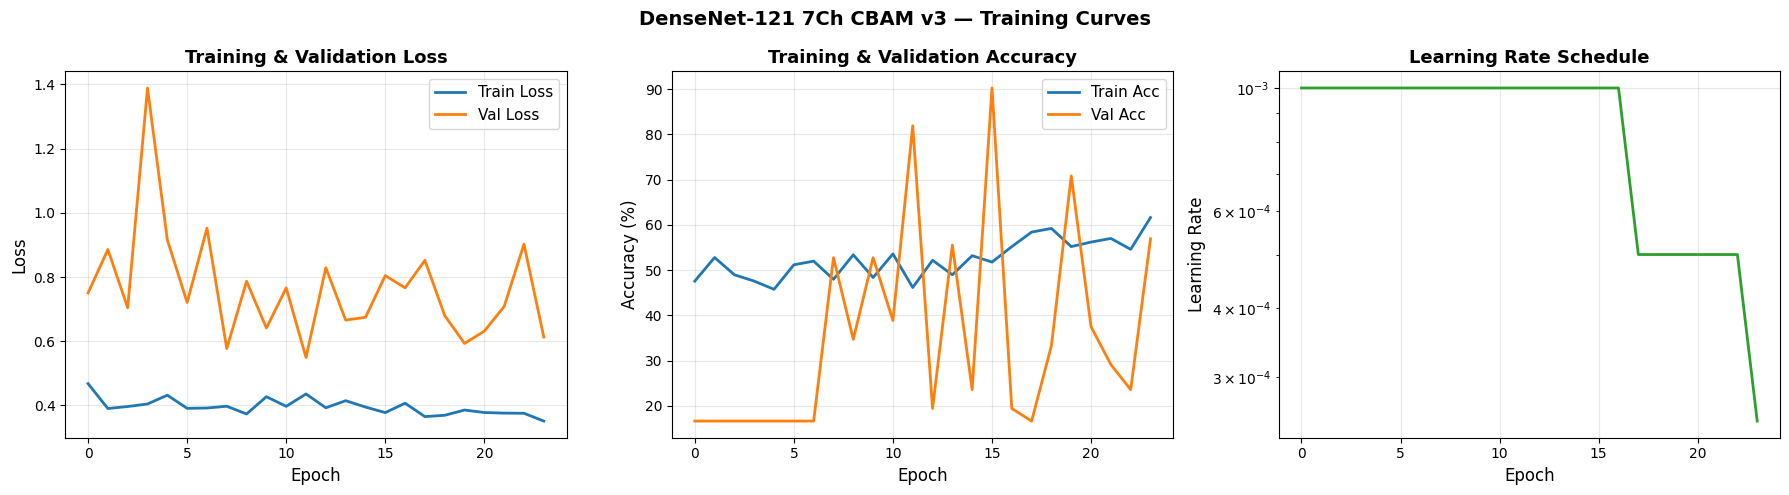

✅ Training curves plotted


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(history['train_loss'], label='Train Loss', linewidth=2, color='#1f77b4')
axes[0].plot(history['val_loss'],   label='Val Loss',   linewidth=2, color='#ff7f0e')
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('Loss', fontsize=12)
axes[0].set_title('Training & Validation Loss', fontweight='bold', fontsize=13)
axes[0].legend(fontsize=11)
axes[0].grid(alpha=0.3)

axes[1].plot(history['train_acc'], label='Train Acc', linewidth=2, color='#1f77b4')
axes[1].plot(history['val_acc'],   label='Val Acc',   linewidth=2, color='#ff7f0e')
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('Accuracy (%)', fontsize=12)
axes[1].set_title('Training & Validation Accuracy', fontweight='bold', fontsize=13)
axes[1].legend(fontsize=11)
axes[1].grid(alpha=0.3)

axes[2].plot(history['learning_rates'], linewidth=2, color='#2ca02c')
axes[2].set_xlabel('Epoch', fontsize=12)
axes[2].set_ylabel('Learning Rate', fontsize=12)
axes[2].set_title('Learning Rate Schedule', fontweight='bold', fontsize=13)
axes[2].set_yscale('log')
axes[2].grid(alpha=0.3)

plt.suptitle(f'DenseNet-121 7Ch CBAM v3 — Training Curves', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'training_curves.png'), dpi=300, bbox_inches='tight')
plt.show()
print("✅ Training curves plotted")


## Model Evaluation


In [ ]:
# Load best model
checkpoint = torch.load(best_model_path)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

print("=" * 60)
print("EVALUATING ON TEST SET")
print("=" * 60)

all_preds, all_labels_e, all_probs = [], [], []

with torch.no_grad():
    for imgs_7ch, labels_b, _ in test_loader:
        imgs_7ch = imgs_7ch.to(device)
        out      = model(imgs_7ch)
        probs    = torch.softmax(out, dim=1)
        _, pred  = torch.max(out, 1)
        all_preds.extend(pred.cpu().numpy())
        all_labels_e.extend(labels_b.numpy())
        all_probs.extend(probs.cpu().numpy())

all_preds    = np.array(all_preds)
all_labels_e = np.array(all_labels_e)
all_probs    = np.array(all_probs)

print("\n📊 Classification Report:")
print("=" * 60)
report = classification_report(
    all_labels_e, all_preds,
    target_names=['Low', 'High-Risk'], digits=4
)
print(report)

roc_auc  = roc_auc_score(all_labels_e, all_probs[:, 1])
pr_auc   = average_precision_score(all_labels_e, all_probs[:, 1])
test_acc = 100.0 * (all_preds == all_labels_e).sum() / len(all_labels_e)

print(f"Test Accuracy : {test_acc:.2f}%")
print(f"ROC-AUC       : {roc_auc:.4f}")
print(f"PR-AUC        : {pr_auc:.4f}")

cm = confusion_matrix(all_labels_e, all_preds)
print(f"\nConfusion Matrix:\n{cm}")
print(f"TN={cm[0,0]}  FP={cm[0,1]}  FN={cm[1,0]}  TP={cm[1,1]}")
print(f"\n⚠️  Clinical note: FN={cm[1,0]} missed High-Risk cases are the critical failure mode.")

with open(os.path.join(OUTPUT_DIR, f'{MODEL_NAME}_classification_report.txt'), 'w') as f:
    f.write(report)


EVALUATING ON TEST SET

📊 Classification Report:
              precision    recall  f1-score   support

         Low     0.9074    0.8305    0.8673       118
   High-Risk     0.4286    0.6000    0.5000        25

    accuracy                         0.7902       143
   macro avg     0.6680    0.7153    0.6836       143
weighted avg     0.8237    0.7902    0.8031       143

Test Accuracy : 79.02%
ROC-AUC       : 0.7766
PR-AUC        : 0.6776

Confusion Matrix:
[[98 20]
 [10 15]]
TN=98  FP=20  FN=10  TP=15

⚠️  Clinical note: FN=10 missed High-Risk cases are the critical failure mode.


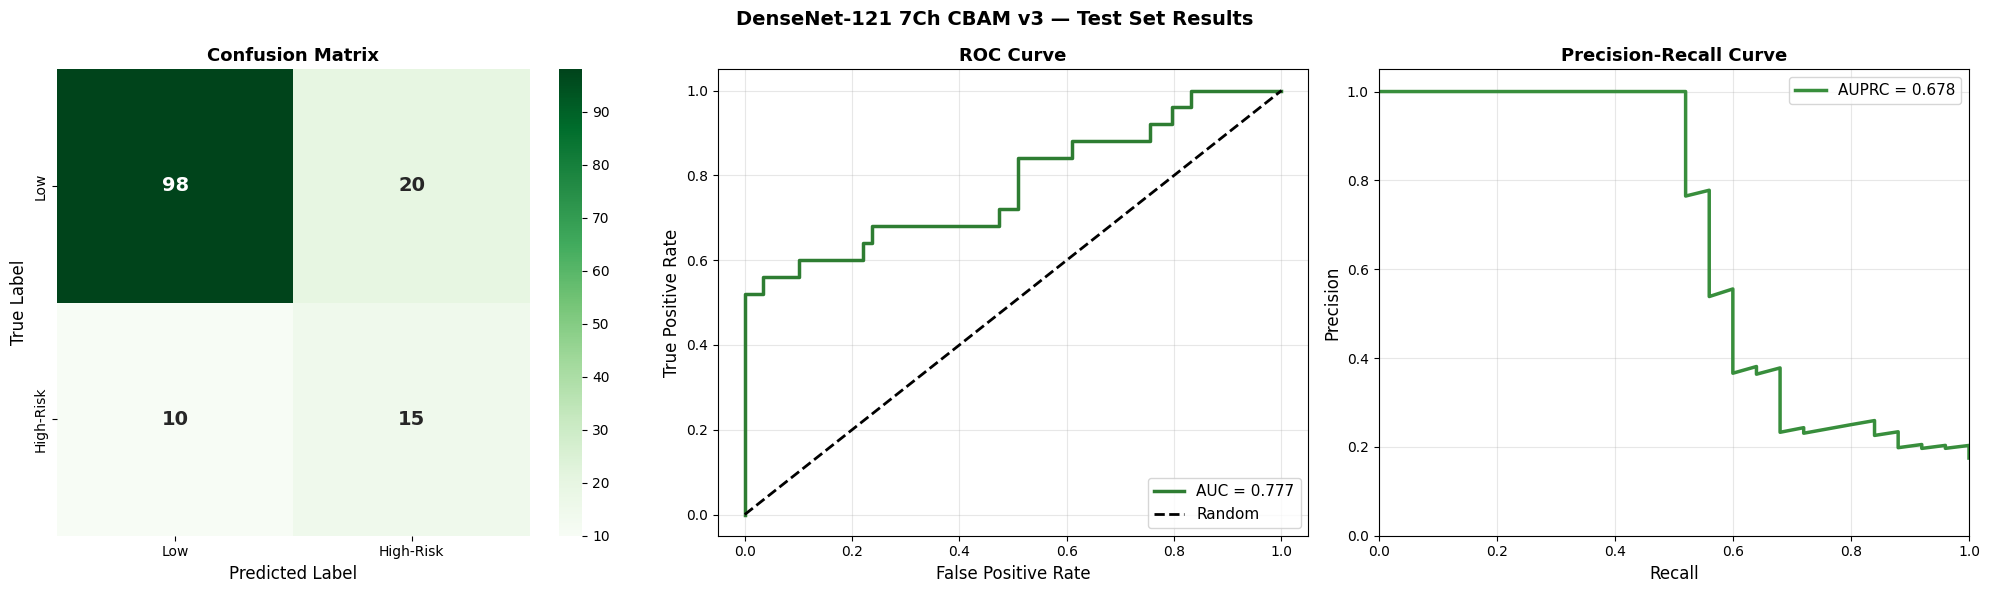

TN=98  FP=20  FN=10  TP=15
ROC-AUC : 0.7766
PR-AUC  : 0.6776


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Confusion Matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', ax=axes[0],
            xticklabels=['Low', 'High-Risk'],
            yticklabels=['Low', 'High-Risk'],
            annot_kws={'size': 14, 'weight': 'bold'})
axes[0].set_title('Confusion Matrix', fontweight='bold', fontsize=13)
axes[0].set_ylabel('True Label', fontsize=12)
axes[0].set_xlabel('Predicted Label', fontsize=12)

# ROC Curve
fpr, tpr, _ = roc_curve(all_labels_e, all_probs[:, 1])
axes[1].plot(fpr, tpr, linewidth=2.5, label=f'AUC = {roc_auc:.3f}', color='#2E7D32')
axes[1].plot([0, 1], [0, 1], 'k--', linewidth=2, label='Random')
axes[1].set_xlabel('False Positive Rate', fontsize=12)
axes[1].set_ylabel('True Positive Rate', fontsize=12)
axes[1].set_title('ROC Curve', fontweight='bold', fontsize=13)
axes[1].legend(fontsize=11, loc='lower right')
axes[1].grid(alpha=0.3)

# Precision-Recall Curve
precision_vals, recall_vals, _ = precision_recall_curve(all_labels_e, all_probs[:, 1])
axes[2].plot(recall_vals, precision_vals, linewidth=2.5,
             label=f'AUPRC = {pr_auc:.3f}', color='#388E3C')
axes[2].set_xlabel('Recall', fontsize=12)
axes[2].set_ylabel('Precision', fontsize=12)
axes[2].set_title('Precision-Recall Curve', fontweight='bold', fontsize=13)
axes[2].legend(fontsize=11, loc='upper right')
axes[2].grid(alpha=0.3)
axes[2].set_xlim([0.0, 1.0])
axes[2].set_ylim([0.0, 1.05])

plt.suptitle('DenseNet-121 7Ch CBAM v3 — Test Set Results', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'evaluation_plots.png'), dpi=300, bbox_inches='tight')
plt.show()

print(f"TN={cm[0,0]}  FP={cm[0,1]}  FN={cm[1,0]}  TP={cm[1,1]}")
print(f"ROC-AUC : {roc_auc:.4f}")
print(f"PR-AUC  : {pr_auc:.4f}")


## Comprehensive Results Summary


In [ ]:
precision_per_class, recall_per_class, f1_per_class, _ = precision_recall_fscore_support(
    all_labels_e, all_preds, average=None
)

print("=" * 60)
print(f"COMPREHENSIVE RESULTS - {MODEL_NAME.upper()}")
print("=" * 60)

print("\n📊 Dataset Statistics:")
print(f"  Total matched samples : {len(df_matched)}")
print(f"  Unique images used    : {len(used_images)}")
print(f"  Test set size         : {len(all_labels_e)}")

print("\n🎯 Overall Performance:")
print(f"  Test Accuracy  : {test_acc:.2f}%")
print(f"  Best Val Acc   : {best_val_acc:.2f}%")
print(f"  ROC-AUC        : {roc_auc:.4f}")
print(f"  PR-AUC         : {pr_auc:.4f}")

print("\n📈 Per-Class Metrics:")
for i, class_name in enumerate(['Low', 'High-Risk']):
    print(f"  {class_name}:")
    print(f"    Precision : {precision_per_class[i]:.4f}")
    print(f"    Recall    : {recall_per_class[i]:.4f}")
    print(f"    F1-Score  : {f1_per_class[i]:.4f}")

print("\n💾 Saved Files:")
print(f"  Model   : {best_model_path}")
print(f"  History : {history_path}")
print(f"  Plots   : {OUTPUT_DIR}/*.png")

print(f"\n✅ Evaluation complete! All results saved to: {OUTPUT_DIR}")


COMPREHENSIVE RESULTS - DENSENET121_7CH_CBAM_V3

📊 Dataset Statistics:
  Total matched samples : 713
  Unique images used    : 375
  Test set size         : 143

🎯 Overall Performance:
  Test Accuracy  : 79.02%
  Best Val Acc   : 81.94%
  ROC-AUC        : 0.7766
  PR-AUC         : 0.6776

📈 Per-Class Metrics:
  Low:
    Precision : 0.9074
    Recall    : 0.8305
    F1-Score  : 0.8673
  High-Risk:
    Precision : 0.4286
    Recall    : 0.6000
    F1-Score  : 0.5000

💾 Saved Files:
  Model   : /content/drive/MyDrive/FINAL_YEAR/binary_results_densenet_7ch_cbam/densenet121_7ch_cbam_v3_best.pth
  History : /content/drive/MyDrive/FINAL_YEAR/binary_results_densenet_7ch_cbam/densenet121_7ch_cbam_v3_history.csv
  Plots   : /content/drive/MyDrive/FINAL_YEAR/binary_results_densenet_7ch_cbam/*.png

✅ Evaluation complete! All results saved to: /content/drive/MyDrive/FINAL_YEAR/binary_results_densenet_7ch_cbam
